# Lesson 8: Object Detection

- In the classroom, the libraries are already installed for you.
- If you would like to run this code on your own machine, you can install the following:

```
    !pip install transformers
    !pip install gradio
    !pip install timm
    !pip install inflect
    !pip install phonemizer
```

**Note:**  `py-espeak-ng` is only available Linux operating systems.

To run locally in a Linux machine, follow these commands:
```
    sudo apt-get update
    sudo apt-get install espeak-ng
    pip install py-espeak-ng
```

### Build the `object-detection` pipeline using 🤗 Transformers Library

- This model was release with the paper [End-to-End Object Detection with Transformers](https://arxiv.org/abs/2005.12872) from Carion et al. (2020)

In [1]:
from helper import load_image_from_url, render_results_in_image

d:\DL Courses\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from transformers import pipeline

- Here is some code that suppresses warning messages.

In [3]:
from transformers.utils import logging
logging.set_verbosity_error()

from helper import ignore_warnings
ignore_warnings()

In [5]:
od_pipe = pipeline("object-detection", "facebook/detr-resnet-50")

Info about [facebook/detr-resnet-50](https://huggingface.co/facebook/detr-resnet-50)

Explore more of the [Hugging Face Hub for more object detection models](https://huggingface.co/models?pipeline_tag=object-detection&sort=trending)

### Use the Pipeline

In [6]:
from PIL import Image

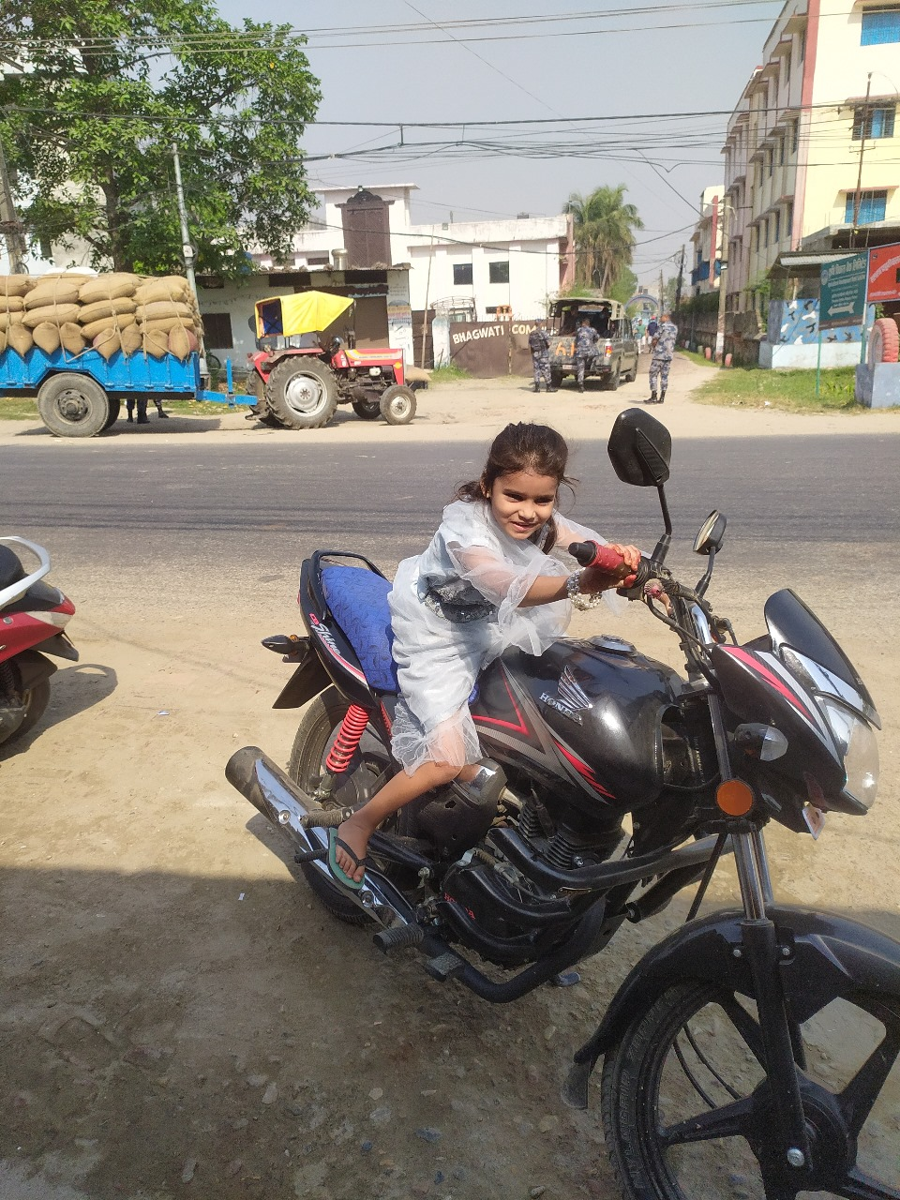

In [8]:
raw_image = Image.open('afrin_demo.jpg')
raw_image.resize((900, 1200))


In [9]:
pipeline_output = od_pipe(raw_image)

- Return the results from the pipeline using the helper function `render_results_in_image`.

In [10]:
processed_image = render_results_in_image(
    raw_image, 
    pipeline_output)

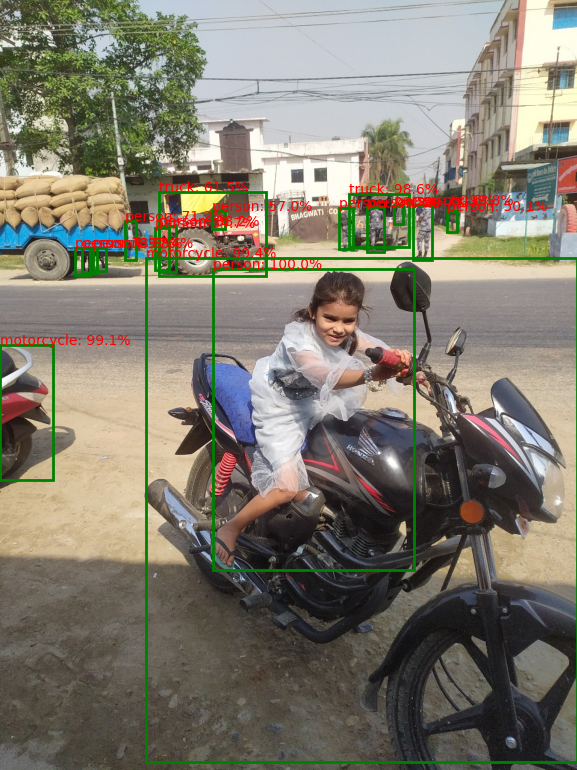

In [11]:
processed_image

### Using `Gradio` as a Simple Interface

- Use [Gradio](https://www.gradio.app) to create a demo for the object detection app.
- The demo makes it look friendly and easy to use.
- You can share the demo with your friends and colleagues as well.

In [12]:
import os
import gradio as gr

In [13]:
def get_pipeline_prediction(pil_image):
    
    pipeline_output = od_pipe(pil_image)
    
    processed_image = render_results_in_image(pil_image,
                                            pipeline_output)
    return processed_image

In [14]:
demo = gr.Interface(
  fn=get_pipeline_prediction,
  inputs=gr.Image(label="Input image", 
                  type="pil"),
  outputs=gr.Image(label="Output image with predicted instances",
                   type="pil")
)

- `share=True` will provide an online link to access to the demo

In [16]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [17]:
demo.close()

Closing server running on port: 7860


### Close the app
- Remember to call `.close()` on the Gradio app when you're done using it.

### Make an AI Powered Audio Assistant

- Combine the object detector with a text-to-speech model that will help dictate what is inside the image.

- Inspect the output of the object detection pipeline.

In [18]:
pipeline_output

[{'score': 0.5473120212554932,
  'label': 'person',
  'box': {'xmin': 257, 'ymin': 378, 'xmax': 281, 'ymax': 448}},
 {'score': 0.9967034459114075,
  'label': 'person',
  'box': {'xmin': 609, 'ymin': 343, 'xmax': 638, 'ymax': 418}},
 {'score': 0.5008738040924072,
  'label': 'person',
  'box': {'xmin': 743, 'ymin': 351, 'xmax': 759, 'ymax': 385}},
 {'score': 0.6061776876449585,
  'label': 'person',
  'box': {'xmin': 654, 'ymin': 340, 'xmax': 669, 'ymax': 372}},
 {'score': 0.9859638214111328,
  'label': 'truck',
  'box': {'xmin': 579, 'ymin': 322, 'xmax': 680, 'ymax': 410}},
 {'score': 0.7333742380142212,
  'label': 'person',
  'box': {'xmin': 125, 'ymin': 412, 'xmax': 149, 'ymax': 457}},
 {'score': 0.6149465441703796,
  'label': 'truck',
  'box': {'xmin': 264, 'ymin': 318, 'xmax': 441, 'ymax': 459}},
 {'score': 0.9912235736846924,
  'label': 'motorcycle',
  'box': {'xmin': 0, 'ymin': 573, 'xmax': 87, 'ymax': 798}},
 {'score': 0.8818091154098511,
  'label': 'person',
  'box': {'xmin': 263

In [19]:
od_pipe

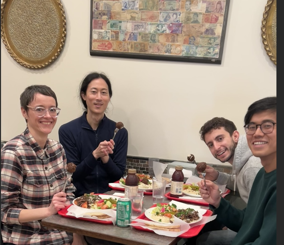

In [17]:
raw_image = Image.open('huggingface_friends.jpg')
raw_image.resize((284, 245))

In [20]:
from helper import summarize_predictions_natural_language

In [21]:
text = summarize_predictions_natural_language(pipeline_output)

In [22]:
text

'In this image, there are thirteen persons two trucks and two motorcycles.'

### Generate Audio Narration of an Image

In [24]:
tts_pipe = pipeline("text-to-speech",
                    model="kakao-enterprise/vits-ljs")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


More info about [kakao-enterprise/vits-ljs](https://huggingface.co/kakao-enterprise/vits-ljs).

In [25]:
narrated_text = tts_pipe(text)

RuntimeError: espeak not installed on your system

### Play the Generated Audio

In [23]:
from IPython.display import Audio as IPythonAudio

In [24]:
IPythonAudio(narrated_text["audio"][0],
             rate=narrated_text["sampling_rate"])

### Try it yourself! 
- Try these models with other images!